# Module 21 — KG-RAG sur IMGT/mAb-KG : interroger le graphe des anticorps thérapeutiques en langage naturel

> **Objectif** : appliquer le module 17 à un vrai cas d'usage, **IMGT/mAb-KG** (le graphe de connaissances des anticorps monoclonaux thérapeutiques d'IMGT). On construit la chaîne complète d'un assistant fiable : **introspection du schéma** (pour coller au graphe réel), **liaison d'entités** avec synonymes (« PD-1 » → PDCD1), **text-to-SPARQL** évalué par l'exactitude d'exécution et réparé par validation, **GraphRAG** avec citations, serveur **MCP** et agent **LangGraph**. On termine par la prédiction de liens (*KG embeddings*) et un piège d'évaluation qui concerne directement les travaux sur IMGT/mAb-KG : la **fuite par relations inverses et chemins redondants**.

| | |
|---|---|
| **Durée estimée** | 4 h |
| **Prérequis** | Modules 15 (outils, MCP), 16 (RAG), 17 (RDF, SPARQL, Fuseki, text-to-SPARQL), 18 (LangGraph) |
| **Librairies** | `numpy`, `scikit-learn`, `pandas`, `matplotlib` ; `SPARQLWrapper`, `rdflib`, `mcp`, `langgraph`, `pykeen` (sections 7–9) |

> ⚠️ **Données.** Je n'ai pas accès à IMGT/mAb-KG depuis cet environnement, et je ne connais pas toutes les IRI exactes de son schéma. Le graphe de démonstration suit le **modèle de données publié** (quatre niveaux : anticorps, construction, produit et études cliniques, mode d'action ; Sanou et al., *Frontiers in Immunology*, 2024), avec des **anticorps fictifs** (noms en `demo…mab`), des cibles et des indications réelles mais des associations simplifiées. Les propriétés sont dans un espace de noms `demo:`, sauf `imgt:hasClinicalIndication` et son inverse, citées dans un préprint de 2025 sur les plongements d'IMGT/mAb-KG. Toute la chaîne est **pilotée par le schéma** : la section 2 montre comment l'extraire automatiquement de ton point d'accès Fuseki, et il suffit alors de remplacer le graphe.

**Plan**

1. Le graphe de démonstration (modèle à quatre niveaux)
2. Introspection du schéma : coller au graphe réel
3. Liaison d'entités : noms, synonymes, variantes
4. Text-to-SPARQL : un jeu de questions, l'exactitude d'exécution, la réparation
5. GraphRAG : répondre avec des faits cités
6. Prédiction de liens : plongements de graphe et fuite par relations inverses
7. En production : Fuseki, point d'accès en lecture seule, délais
8. Un serveur MCP pour IMGT/mAb-KG (et ProtAnnotML)
9. Un agent LangGraph : router, lier, interroger, vérifier
10. Récapitulatif et exercices

In [1]:
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

## 1. Le graphe de démonstration (modèle à quatre niveaux)

Le modèle de données d'IMGT/mAb-KG s'organise en quatre niveaux :
- **l'anticorps** (substance pharmacologique, avec son nom DCI/INN), ses **cibles** dans un taxon, son clone d'origine, ses biosimilaires ;
- **la construction** : format du récepteur, composants moléculaires, **segments** (chaînes, domaines, gènes IMGT utilisés), reliés à la construction par une relation « partie de » ;
- **le produit** et ses **études cliniques**, chacune avec une indication, une phase, un promoteur ;
- **le mode d'action** : effets (relation « a pour effet »), domaine clinique, références bibliographiques.

On génère un graphe fictif qui suit cette structure. Les cibles et indications sont réelles (avec des associations simplifiées : par exemple PD-1 avec mélanome et cancer du poumon), les anticorps et entreprises sont inventés.

In [2]:
def lit(v):
    return f'"{v}"^^xsd:integer' if isinstance(v, (int, np.integer)) else f'"{v}"'


def py(term):
    m = re.fullmatch(r'"(.*)"(?:\^\^xsd:(\w+))?', term)
    return term if not m else int(m.group(1)) if m.group(2) == "integer" else m.group(1)


TARGETS = {   # symbol: (synonyms, indications, effect)
    "PDCD1": (["PD-1", "CD279"], ["melanoma", "non-small cell lung cancer", "renal cell carcinoma"], "immune checkpoint blockade"),
    "CD274": (["PD-L1", "B7-H1"], ["non-small cell lung cancer", "urothelial carcinoma", "melanoma"], "immune checkpoint blockade"),
    "ERBB2": (["HER2", "HER-2/neu"], ["breast cancer", "gastric cancer"], "receptor signalling inhibition"),
    "EGFR": (["HER1", "ErbB1"], ["colorectal cancer", "head and neck cancer", "non-small cell lung cancer"], "receptor signalling inhibition"),
    "MS4A1": (["CD20"], ["B-cell lymphoma", "chronic lymphocytic leukemia", "rheumatoid arthritis", "multiple sclerosis"], "B-cell depletion"),
    "CD19": (["B4"], ["B-cell lymphoma", "acute lymphoblastic leukemia"], "B-cell depletion"),
    "TNF": (["TNF-alpha", "TNFA"], ["rheumatoid arthritis", "psoriasis", "Crohn disease"], "cytokine neutralization"),
    "IL6R": (["CD126"], ["rheumatoid arthritis", "giant cell arteritis"], "cytokine receptor blockade"),
    "VEGFA": (["VEGF"], ["colorectal cancer", "age-related macular degeneration"], "angiogenesis inhibition"),
    "LAG3": (["CD223"], ["melanoma"], "immune checkpoint blockade"),
    "CTLA4": (["CD152"], ["melanoma", "renal cell carcinoma"], "immune checkpoint blockade"),
    "TNFRSF17": (["BCMA", "CD269"], ["multiple myeloma"], "T-cell redirection"),
    "CD3E": (["CD3"], [], "T-cell redirection"),
}
FORMATS = ["IgG1", "IgG1", "IgG1", "IgG4", "IgG4", "bispecific IgG", "ADC IgG1", "VHH-Fc"]
ORIGINS = {"zu": "humanized", "xi": "chimeric", "u": "human"}
PHASES = ["phase 1", "phase 2", "phase 3", "approved"]
COMPANIES = [f"Demo Pharma {c}" for c in "ABCDEFGH"]
SYLL = ["ka", "lo", "ri", "ve", "na", "to", "si", "mu", "be", "da", "fe", "go"]
VGENES = [f"DEMO-IGHV{f}-{g}" for f in (1, 3, 4) for g in (1, 2, 3)]

T = set()
add = lambda s, p, o: T.add((s, p, o))
slug = lambda x: re.sub(r"[^A-Za-z0-9]+", "_", x).strip("_")
for sym, (syn, inds, eff) in TARGETS.items():
    t = f"demo:target_{sym}"
    add(t, "rdf:type", "demo:Target"); add(t, "rdfs:label", lit(sym))
    for s_ in syn:
        add(t, "skos:altLabel", lit(s_))
    for ind in inds:
        add(f"demo:ind_{slug(ind)}", "rdf:type", "demo:ClinicalIndication"); add(f"demo:ind_{slug(ind)}", "rdfs:label", lit(ind))
    add(f"demo:effect_{slug(eff)}", "rdf:type", "demo:Effect"); add(f"demo:effect_{slug(eff)}", "rdfs:label", lit(eff))

mabs, names = [], set()
tumor_targets = ["ERBB2", "EGFR", "MS4A1", "CD19", "TNFRSF17"]
for i in range(70):
    infix = str(rng.choice(list(ORIGINS)))
    while True:
        name = "demo" + "".join(rng.choice(SYLL, size=2)) + infix + "mab"
        if name not in names:
            names.add(name); break
    m = f"demo:mab_{name}"
    fmt = str(rng.choice(FORMATS))
    if fmt == "bispecific IgG":
        targets = ["CD3E", str(rng.choice(tumor_targets))]
    else:
        targets = [str(rng.choice([t_ for t_ in TARGETS if t_ != "CD3E"]))]
    main = targets[-1]
    add(m, "rdf:type", "demo:MonoclonalAntibody"); add(m, "rdfs:label", lit(name))
    add(m, "demo:hasOrigin", lit(ORIGINS[infix]))
    for t_ in targets:
        add(m, "demo:targets", f"demo:target_{t_}")
    add(m, "demo:hasEffect", f"demo:effect_{slug(TARGETS[main][2])}")
    c = f"demo:construct_{name}"                                     # construct level
    add(m, "demo:hasConstruct", c); add(c, "rdf:type", "demo:Construct"); add(c, "demo:hasReceptorFormat", lit(fmt))
    seg = f"demo:segment_{name}_H"
    add(seg, "rdf:type", "demo:Segment"); add(seg, "demo:partOf", c); add(seg, "demo:usesGene", lit(str(rng.choice(VGENES))))
    prod = f"demo:product_{name}"                                     # product / clinical level
    add(m, "demo:hasProduct", prod); add(prod, "rdf:type", "demo:Product")
    company = str(rng.choice(COMPANIES))
    for k in range(int(rng.integers(1, 4))):
        ind = str(rng.choice(TARGETS[main][1]))
        st = f"demo:study_{name}_{k}"
        add(prod, "demo:hasStudy", st); add(st, "rdf:type", "demo:ClinicalStudy")
        add(st, "demo:studiesIndication", f"demo:ind_{slug(ind)}"); add(st, "demo:hasPhase", lit(str(rng.choice(PHASES))))
        add(st, "demo:sponsor", lit(company))
        add(m, "imgt:hasClinicalIndication", f"demo:ind_{slug(ind)}")                # direct (derived) relation
        add(f"demo:ind_{slug(ind)}", "imgt:isClincicalIndicationOf", m)              # inverse, spelled as in the 2025 preprint
    mabs.append(m)
print(f"{len(T)} triples, {len(mabs)} monoclonal antibodies, {len(TARGETS)} targets, "
      f"{len({o for s, p, o in T if p == 'imgt:hasClinicalIndication'})} indications")

1930 triples, 70 monoclonal antibodies, 13 targets, 17 indications


> 🔎 **Sur l'orthographe de l'inverse.** Le préprint de 2025 écrit la relation inverse `imgt:isClincicalIndicationOf`. Si c'est bien l'IRI du graphe, c'est un piège pour un LLM : il écrira spontanément `isClinicalIndicationOf` (orthographe correcte), requête invalide. La validation par prédicats connus l'attrape (section 4) ; une solution durable est d'ajouter un alias correctement orthographié déclaré `owl:equivalentProperty`.

## 2. Introspection du schéma : coller au graphe réel

Le prompt de text-to-SPARQL doit contenir le schéma **réel**, pas celui qu'on croit. On l'extrait du graphe lui-même : classes et effectifs, prédicats et effectifs, et surtout les **signatures observées** (type du sujet → prédicat → type de l'objet ou type de littéral), avec un exemple de valeur. C'est plus fiable que les `rdfs:domain`/`rdfs:range` déclarés, qui peuvent manquer ou être trop généraux.

In [3]:
def introspect(triples, max_examples=1):
    types = defaultdict(set)
    for s, p, o in triples:
        if p == "rdf:type":
            types[s].add(o)
    class_count = Counter(o for s, p, o in triples if p == "rdf:type")
    sig, examples = Counter(), {}
    for s, p, o in triples:
        if p == "rdf:type":
            continue
        st_ = "|".join(sorted(types.get(s, {"?"})))
        ot_ = "literal" if o.startswith('"') else "|".join(sorted(types.get(o, {"?"})))
        sig[(st_, p, ot_)] += 1
        examples.setdefault((st_, p, ot_), o)
    return class_count, sig, examples


def schema_prompt(triples):
    class_count, sig, examples = introspect(triples)
    lines = ["Classes (instances):"] + [f"  {c} ({n})" for c, n in class_count.most_common()]
    lines.append("Observed predicates: subject type -> predicate -> object type   (count; example object)")
    for (st_, p, ot_), n in sorted(sig.items(), key=lambda kv: (kv[0][0], -kv[1])):
        ex = examples[(st_, p, ot_)]
        lines.append(f"  {st_} -> {p} -> {ot_}   ({n}; e.g. {ex if ex.startswith(chr(34)) else ex})")
    lines.append("Labels: rdfs:label (official name), skos:altLabel (synonyms). Prefixes: demo:, imgt:, rdf:, rdfs:, skos:, xsd:")
    return "\n".join(lines)

SCHEMA = schema_prompt(T)
print(SCHEMA)

Classes (instances):
  demo:ClinicalStudy (143)
  demo:Construct (70)
  demo:Segment (70)
  demo:Product (70)
  demo:MonoclonalAntibody (70)
  demo:ClinicalIndication (18)
  demo:Target (13)
  demo:Effect (7)
Observed predicates: subject type -> predicate -> object type   (count; example object)
  demo:ClinicalIndication -> imgt:isClincicalIndicationOf -> demo:MonoclonalAntibody   (99; e.g. demo:mab_demogoriumab)
  demo:ClinicalIndication -> rdfs:label -> literal   (18; e.g. "breast cancer")
  demo:ClinicalStudy -> demo:studiesIndication -> demo:ClinicalIndication   (143; e.g. demo:ind_renal_cell_carcinoma)
  demo:ClinicalStudy -> demo:sponsor -> literal   (143; e.g. "Demo Pharma D")
  demo:ClinicalStudy -> demo:hasPhase -> literal   (143; e.g. "phase 3")
  demo:Construct -> demo:hasReceptorFormat -> literal   (70; e.g. "bispecific IgG")
  demo:Effect -> rdfs:label -> literal   (7; e.g. "cytokine neutralization")
  demo:MonoclonalAntibody -> imgt:hasClinicalIndication -> demo:ClinicalI

Sur ton point d'accès Fuseki, les mêmes informations s'obtiennent en SPARQL (à exécuter une fois, puis à mettre en cache : sur un grand graphe, ces requêtes sont coûteuses) :

In [ ]:
INTROSPECTION = {
    "classes": "SELECT ?c (COUNT(?s) AS ?n) WHERE { ?s a ?c } GROUP BY ?c ORDER BY DESC(?n)",
    "predicates": "SELECT ?p (COUNT(*) AS ?n) WHERE { ?s ?p ?o } GROUP BY ?p ORDER BY DESC(?n)",
    "signatures": """SELECT ?ts ?p ?to (COUNT(*) AS ?n) WHERE {
                       ?s ?p ?o . ?s a ?ts . OPTIONAL { ?o a ?to }
                     } GROUP BY ?ts ?p ?to ORDER BY ?ts DESC(?n)""",
    "literal_types": "SELECT ?p (SAMPLE(DATATYPE(?o)) AS ?dt) (SAMPLE(?o) AS ?ex) WHERE { ?s ?p ?o FILTER(isLiteral(?o)) } GROUP BY ?p",
}

## 3. Liaison d'entités : noms, synonymes, variantes

Les utilisateurs écrivent « PD-1 », « pd1 », « anti-HER2 », un nom d'anticorps mal orthographié, ou une indication en français. La liaison d'entités par **n-grammes de caractères** (module 17) sur les libellés **et les synonymes** (`skos:altLabel`) règle la majorité des cas. Pour les indications, un dictionnaire français → anglais (ou les libellés multilingues des ontologies réutilisées, comme MONDO ou NCIt) complète le dispositif.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

LINKABLE_TYPES = {"demo:MonoclonalAntibody", "demo:Target", "demo:ClinicalIndication"}
typed = {s: o for s, p, o in T if p == "rdf:type" and o in LINKABLE_TYPES}
surface = [(py(o), s) for s, p, o in T if p in ("rdfs:label", "skos:altLabel") and s in typed]
FR_EN = {"mélanome": "melanoma", "cancer du sein": "breast cancer", "polyarthrite rhumatoïde": "rheumatoid arthritis",
         "myélome multiple": "multiple myeloma", "lymphome b": "B-cell lymphoma", "cancer du poumon": "non-small cell lung cancer",
         "psoriasis": "psoriasis", "cancer colorectal": "colorectal cancer"}
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), lowercase=True).fit([s for s, _ in surface])
M_surface = vec.transform([s for s, _ in surface])


def link(mention, types=None, threshold=0.5):
    m = FR_EN.get(mention.lower().strip(), mention)
    sims = (M_surface @ vec.transform([m]).T).toarray().ravel()
    for k in np.argsort(-sims):
        label, iri = surface[k]
        if types is None or typed[iri] in types:
            return (iri, label, round(float(sims[k]), 2)) if sims[k] >= threshold else None
    return None

some_mab = py(next(o for s, p, o in T if s == mabs[3] and p == "rdfs:label"))
for mention in ["PD-1", "pd1", "her-2", "CD20", "BCMA", "mélanome", "cancer du sein", some_mab, some_mab[:-3] + "mabb", "PD-L1"]:
    print(f"{mention:22s} -> {link(mention)}")

PD-1                   -> ('demo:target_PDCD1', 'PD-1', 1.0)
pd1                    -> ('demo:target_PDCD1', 'PDCD1', 0.59)
her-2                  -> ('demo:target_ERBB2', 'HER-2/neu', 0.62)
CD20                   -> ('demo:target_MS4A1', 'CD20', 1.0)
BCMA                   -> ('demo:target_TNFRSF17', 'BCMA', 1.0)
mélanome               -> ('demo:ind_melanoma', 'melanoma', 1.0)
cancer du sein         -> ('demo:ind_breast_cancer', 'breast cancer', 1.0)
demoriloumab           -> ('demo:mab_demoriloumab', 'demoriloumab', 1.0)
demoriloumabb          -> ('demo:mab_demoriloumab', 'demoriloumab', 0.97)
PD-L1                  -> ('demo:target_CD274', 'PD-L1', 1.0)


> ⚠️ « PD-1 » et « PD-L1 » sont à une lettre l'un de l'autre, et désignent des cibles différentes dont les anticorps ont des indications proches : une erreur de liaison donnerait une réponse **plausible et fausse**. Pour les cibles, exige une correspondance exacte sur un libellé ou un synonyme quand elle existe, et ne recours au flou qu'en dernier ressort, en le signalant à l'utilisateur.

In [5]:
def link_strict(mention, types=None):
    """Exact (case/space-insensitive) match on labels and synonyms first; fuzzy fallback flagged as such."""
    norm = lambda x: re.sub(r"[\s_]+", "", x.lower())
    m = FR_EN.get(mention.lower().strip(), mention)
    exact = [(iri, lab) for lab, iri in surface if norm(lab) == norm(m) and (types is None or typed[iri] in types)]
    if exact:
        return dict(iri=exact[0][0], label=exact[0][1], match="exact")
    fuzzy = link(m, types)
    return dict(iri=fuzzy[0], label=fuzzy[1], match=f"fuzzy ({fuzzy[2]})") if fuzzy else None

for mention in ["PD-1", "pd-l1", "PDL1", "Her2"]:
    print(f"{mention:8s} -> {link_strict(mention, {'demo:Target'})}")

PD-1     -> {'iri': 'demo:target_PDCD1', 'label': 'PD-1', 'match': 'exact'}
pd-l1    -> {'iri': 'demo:target_CD274', 'label': 'PD-L1', 'match': 'exact'}
PDL1     -> {'iri': 'demo:target_CD274', 'label': 'PD-L1', 'match': 'fuzzy (0.6)'}
Her2     -> {'iri': 'demo:target_ERBB2', 'label': 'HER2', 'match': 'exact'}


## 4. Text-to-SPARQL : un jeu de questions, l'exactitude d'exécution, la réparation

On reprend le **mini-moteur SPARQL** du module 17 (sous-ensemble : `SELECT [DISTINCT]`, motifs, `FILTER`, `LIMIT`) et on le complète d'un **jeu d'évaluation** : des questions réalistes avec leur requête de **référence**. On compare les **résultats** (ensembles de lignes), pas le texte des requêtes : deux requêtes différentes peuvent être également justes. C'est l'**exactitude d'exécution**.

In [6]:
class MiniSPARQL:
    """Small SPARQL subset over (s, p, o) string triples (same engine as module 17, condensed)."""

    def __init__(self, triples):
        self.T = set(triples)
        self.idx = defaultdict(set)
        for t in self.T:
            for pos in range(3):
                self.idx[(pos, t[pos])].add(t)

    def parse(self, query):
        q = re.sub(r"PREFIX\s+\w+:\s*<[^>]+>", "", re.sub(r"#[^\n]*", "", query), flags=re.I)
        if re.search(r"\b(INSERT|DELETE|LOAD|CLEAR|DROP|CREATE)\b", q, re.I):
            raise ValueError("update operations are not allowed (read-only engine)")
        m = re.search(r"SELECT\s+(DISTINCT\s+)?(.*?)\s+WHERE\s*\{(.*)\}\s*(?:LIMIT\s+(\d+))?\s*$", q, re.S | re.I)
        if not m:
            raise ValueError("cannot parse: expected SELECT ... WHERE { ... } [LIMIT n]")
        distinct, sel, body, limit = m.groups()
        filters = re.findall(r"FILTER\s*\((.*?)\)\s*(?=\.|$|\?|\w+:|FILTER)", body + " ", re.S | re.I)
        body = re.sub(r"FILTER\s*\(.*?\)\s*(?=\.|$|\?|\w+:|FILTER)", " ", body + " ", flags=re.S | re.I)
        patterns, subject = [], None
        for stmt in [s.strip() for s in re.split(r"\s\.\s|\s\.$", body + " ") if s.strip()]:
            for k, part in enumerate(stmt.split(";")):
                toks = re.findall(r'"[^"]*"(?:\^\^\w+:\w+)?|\S+', part.strip())
                if not toks:
                    continue
                if k == 0:
                    subject, toks = toks[0], toks[1:]
                for o in " ".join(toks[1:]).split(","):
                    patterns.append((subject, toks[0], o.strip()))
        return {"vars": re.findall(r"\?\w+", sel), "distinct": bool(distinct), "patterns": patterns,
                "filters": filters, "limit": int(limit) if limit else None}

    def match(self, pattern, b):
        s, p, o = (b.get(x, x) for x in pattern)
        cands = None
        for pos, val in enumerate((s, p, o)):
            if not val.startswith("?"):
                cands = self.idx[(pos, val)] if cands is None else cands & self.idx[(pos, val)]
        for t in (self.T if cands is None else cands):
            nb, ok = dict(b), True
            for var, val in zip((s, p, o), t):
                if var.startswith("?"):
                    if nb.get(var, val) != val:
                        ok = False; break
                    nb[var] = val
            if ok:
                yield nb

    def check_filter(self, f, b):
        expr = f
        for var in sorted(set(re.findall(r"\?\w+", f)), key=len, reverse=True):
            if var not in b:
                return False
            expr = expr.replace(var, repr(py(b[var])))
        expr = expr.replace("&&", " and ").replace("||", " or ")
        expr = re.sub(r"(?<![<>!=])=(?!=)", "==", expr)
        return bool(eval(expr, {"__builtins__": {}}, {}))            # toy engine: filters are validated upstream

    def select(self, query):
        q = self.parse(query)
        results = [{}]
        for pat in sorted(q["patterns"], key=lambda t: sum(x.startswith("?") for x in t)):
            results = [nb for b in results for nb in self.match(pat, b)]
        results = [b for b in results if all(self.check_filter(f, b) for f in q["filters"])]
        rows = [tuple(b.get(v) for v in q["vars"]) for b in results]
        if q["distinct"]:
            rows = list(dict.fromkeys(rows))
        rows.sort(key=lambda r: [str(x) for x in r])
        return rows[: q["limit"]] if q["limit"] else rows

kg = MiniSPARQL(T)
KNOWN_PREDICATES = {p for _, p, _ in T}
KNOWN_PREFIXES = {"demo", "imgt", "rdf", "rdfs", "skos", "xsd"}


def validate(query, engine=kg, max_limit=200):
    if re.search(r"\b(INSERT|DELETE|LOAD|CLEAR|DROP|CREATE)\b", query, re.I):
        return None, ["read-only endpoint: updates are forbidden"]
    try:
        parsed = engine.parse(query)
    except ValueError as e:
        return None, [f"syntax error: {e}"]
    errors = []
    for s, p, o in parsed["patterns"]:
        for term in (s, p, o):
            m = re.match(r"(\w+):", term)
            if m and not term.startswith('"') and m.group(1) not in KNOWN_PREFIXES:
                errors.append(f"unknown prefix {m.group(1)}:")
        if not p.startswith("?") and p not in KNOWN_PREDICATES:
            close = [k for k in KNOWN_PREDICATES if k.split(":")[-1].lower()[:6] == p.split(":")[-1].lower()[:6]]
            errors.append(f"unknown predicate {p}" + (f" (did you mean {close[0]}?)" if close else ""))
    if errors:
        return None, errors
    return (query if re.search(r"LIMIT\s+\d+", query, re.I) else query.rstrip() + f" LIMIT {max_limit}"), []

Le jeu d'évaluation : des questions comme en poseraient des utilisateurs d'IMGT, avec la requête de référence écrite par un expert (toi, dans le cas réel). Quelques entités sont choisies dans le graphe fictif pour que chaque question ait une réponse.

In [7]:
mab0 = py(next(o for s, p, o in T if s == mabs[0] and p == "rdfs:label"))
bisp = next(s for s, p, o in T if p == "demo:targets" and o == "demo:target_CD3E")
bisp_name = py(next(o for s, p, o in T if s == bisp and p == "rdfs:label"))
EVAL = [
    dict(q="Quels anticorps ciblent PD-1 ?",
         gold="SELECT DISTINCT ?name WHERE { ?m demo:targets demo:target_PDCD1 ; rdfs:label ?name . }"),
    dict(q="Quelles sont les indications cliniques des anticorps anti-HER2 ?",
         gold="SELECT DISTINCT ?ind WHERE { ?m demo:targets demo:target_ERBB2 ; imgt:hasClinicalIndication ?i . ?i rdfs:label ?ind . }"),
    dict(q=f"Quelle est la cible de {mab0} ?",
         gold=f'SELECT DISTINCT ?t WHERE {{ ?m rdfs:label "{mab0}" ; demo:targets ?x . ?x rdfs:label ?t . }}'),
    dict(q="Quels anticorps sont étudiés en phase 3 dans le mélanome ?",
         gold='SELECT DISTINCT ?name WHERE { ?m rdfs:label ?name ; demo:hasProduct ?p . ?p demo:hasStudy ?s . ?s demo:studiesIndication demo:ind_melanoma ; demo:hasPhase "phase 3" . }'),
    dict(q="Quels anticorps bispécifiques engagent CD3, et avec quelle seconde cible ?",
         gold='SELECT DISTINCT ?name ?t WHERE { ?m demo:targets demo:target_CD3E ; demo:targets ?x ; rdfs:label ?name . ?x rdfs:label ?t . FILTER(?t != "CD3E") }'),
    dict(q="Quels gènes IGHV sont utilisés par les anticorps anti-CD20 ?",
         gold="SELECT DISTINCT ?gene WHERE { ?m demo:targets demo:target_MS4A1 ; demo:hasConstruct ?c . ?seg demo:partOf ?c ; demo:usesGene ?gene . }"),
    dict(q="Quels anticorps humanisés ont un format IgG4 ?",
         gold='SELECT DISTINCT ?name WHERE { ?m demo:hasOrigin "humanized" ; rdfs:label ?name ; demo:hasConstruct ?c . ?c demo:hasReceptorFormat "IgG4" . }'),
    dict(q="Quels anticorps ont pour effet le blocage de points de contrôle immunitaire ?",
         gold="SELECT DISTINCT ?name WHERE { ?m demo:hasEffect demo:effect_immune_checkpoint_blockade ; rdfs:label ?name . }"),
]
for e in EVAL:
    e["gold_rows"] = set(kg.select(e["gold"]))
    print(f"{len(e['gold_rows']):3d} rows | {e['q']}")

  7 rows | Quels anticorps ciblent PD-1 ?
  1 rows | Quelles sont les indications cliniques des anticorps anti-HER2 ?
  1 rows | Quelle est la cible de demomusiumab ?
  7 rows | Quels anticorps sont étudiés en phase 3 dans le mélanome ?
 12 rows | Quels anticorps bispécifiques engagent CD3, et avec quelle seconde cible ?
  4 rows | Quels gènes IGHV sont utilisés par les anticorps anti-CD20 ?
  1 rows | Quels anticorps humanisés ont un format IgG4 ?
 18 rows | Quels anticorps ont pour effet le blocage de points de contrôle immunitaire ?


Un LLM simulé produit, pour chaque question, une première requête puis, si on lui renvoie une erreur, une requête réparée. Il reproduit les **erreurs typiques** observées avec de vrais modèles : prédicat inventé (`demo:hasTarget`), orthographe « corrigée » de l'inverse, synonyme non lié (« PD-1 » comme libellé), oubli d'un saut (étude → indication), et une requête **valide mais fausse** (filtre oublié), que la validation ne peut pas attraper.

In [8]:
class MockText2SPARQL:
    """Simulated LLM with realistic first-attempt errors; repairs when given validator feedback."""
    ATTEMPTS = {
        0: ['SELECT DISTINCT ?name WHERE { ?m demo:hasTarget ?t ; rdfs:label ?name . ?t rdfs:label "PD-1" . }',          # invented predicate
            'SELECT DISTINCT ?name WHERE { ?m demo:targets ?t ; rdfs:label ?name . ?t rdfs:label "PD-1" . }',             # synonym not linked
            "SELECT DISTINCT ?name WHERE { ?m demo:targets demo:target_PDCD1 ; rdfs:label ?name . }"],
        1: ["SELECT DISTINCT ?ind WHERE { ?i imgt:isClinicalIndicationOf ?m . ?m demo:targets demo:target_ERBB2 . ?i rdfs:label ?ind . }",   # 'corrected' spelling
            "SELECT DISTINCT ?ind WHERE { ?i imgt:isClincicalIndicationOf ?m . ?m demo:targets demo:target_ERBB2 . ?i rdfs:label ?ind . }"],
        2: [None],                                                                                                     # gold, written by the model
        3: ['SELECT DISTINCT ?name WHERE { ?m rdfs:label ?name ; demo:studiesIndication demo:ind_melanoma ; demo:hasPhase "phase 3" . }',   # missing hops
            'SELECT DISTINCT ?name WHERE { ?m rdfs:label ?name ; demo:hasProduct ?p . ?p demo:hasStudy ?s . ?s demo:studiesIndication demo:ind_melanoma ; demo:hasPhase "phase 3" . }'],
        4: ["SELECT DISTINCT ?name ?t WHERE { ?m demo:targets demo:target_CD3E ; demo:targets ?x ; rdfs:label ?name . ?x rdfs:label ?t . }"],   # valid but wrong: forgets the filter
        5: [None],
        6: ['SELECT DISTINCT ?name WHERE { ?m demo:hasOrigin "humanized" ; rdfs:label ?name ; demo:hasReceptorFormat "IgG4" . }',        # format is on the construct
            'SELECT DISTINCT ?name WHERE { ?m demo:hasOrigin "humanized" ; rdfs:label ?name ; demo:hasConstruct ?c . ?c demo:hasReceptorFormat "IgG4" . }'],
        7: [None],
    }

    def generate(self, k, attempt):
        seq = self.ATTEMPTS[k]
        q = seq[min(attempt, len(seq) - 1)]
        return EVAL[k]["gold"] if q is None else q


def run_text_to_sparql(k, llm, repair=True, max_attempts=3):
    log = []
    for attempt in range(max_attempts if repair else 1):
        q = llm.generate(k, attempt)
        safe, errors = validate(q)
        if errors:
            log.append(f"invalid: {errors[0]}"); continue
        rows = set(kg.select(safe))
        if not rows:
            log.append("valid but EMPTY result -> feedback: check entity IRIs (use the linker) and the path through the schema")
            continue
        log.append(f"ok ({len(rows)} rows)")
        return rows, log
    return set(), log

summary = []
llm = MockText2SPARQL()
for repair in (False, True):
    for k, e in enumerate(EVAL):
        rows, log = run_text_to_sparql(k, llm, repair=repair)
        summary.append(dict(repair=repair, question=e["q"][:60], exact=rows == e["gold_rows"], attempts=len(log), trace=" | ".join(log)[:120]))
s = pd.DataFrame(summary)
print(s[s.repair].drop(columns="repair").to_string(index=False))
print("\nexecution accuracy without repair:", f"{s[~s.repair].exact.mean():.0%}", "| with validation + repair:", f"{s[s.repair].exact.mean():.0%}")

                                                    question  exact  attempts                                                                                                                    trace
                              Quels anticorps ciblent PD-1 ?   True         3 invalid: unknown predicate demo:hasTarget | valid but EMPTY result -> feedback: check entity IRIs (use the linker) and t
Quelles sont les indications cliniques des anticorps anti-HE   True         2        invalid: unknown predicate imgt:isClinicalIndicationOf (did you mean imgt:isClincicalIndicationOf?) | ok (1 rows)
                       Quelle est la cible de demomusiumab ?   True         1                                                                                                              ok (1 rows)
  Quels anticorps sont étudiés en phase 3 dans le mélanome ?   True         2     valid but EMPTY result -> feedback: check entity IRIs (use the linker) and the path through the schema | ok (7 rows)
Quels

Lecture :
- la boucle **valider → réparer** récupère les erreurs **détectables** : prédicat inconnu, orthographe de l'inverse, résultat vide (synonyme non lié, sauts oubliés) ;
- elle ne peut rien contre une requête **valide mais fausse** (question 5 : le filtre qui exclut CD3 lui-même est oublié). Seul un jeu d'évaluation avec des réponses de référence révèle ce type d'erreur ; c'est pourquoi l'**exactitude d'exécution** sur un jeu de questions écrit par des experts IMGT est la métrique à suivre, version après version du prompt ou du modèle ;
- en pratique, ajouter au prompt des **exemples** question → requête proches de la question posée (*few-shot* dynamique, module 17) réduit fortement les erreurs de chemin (sauts oubliés).

## 5. GraphRAG : répondre avec des faits cités

Pour les questions ouvertes (« Que sait-on de tel anticorps ? »), on extrait le sous-graphe autour de l'entité liée et on le verbalise en faits numérotés, que le modèle doit citer. Le sous-graphe suit les **niveaux** du modèle (anticorps → construction → segments ; anticorps → produit → études), sans traverser les classes.

In [9]:
PRED_FR = {"demo:targets": "cible", "demo:hasOrigin": "a pour origine", "demo:hasEffect": "a pour effet",
           "demo:hasConstruct": "a pour construction", "demo:hasReceptorFormat": "a pour format", "demo:partOf": "fait partie de",
           "demo:usesGene": "utilise le gène", "demo:hasProduct": "a pour produit", "demo:hasStudy": "est évalué dans l'étude",
           "demo:studiesIndication": "porte sur l'indication", "demo:hasPhase": "est en", "demo:sponsor": "est promue par",
           "imgt:hasClinicalIndication": "a pour indication clinique"}
labels = {s: py(o) for s, p, o in T if p == "rdfs:label"}


def neighborhood(seed, hops=3, max_facts=40):
    frontier, seen, facts = {seed}, {seed}, []
    for _ in range(hops):
        nxt = set()
        for s, p, o in sorted(T):
            if p in ("rdf:type", "rdfs:label", "skos:altLabel", "imgt:isClincicalIndicationOf"):
                continue
            if (s in frontier or (o in frontier and p == "demo:partOf")) and (s, p, o) not in facts:
                facts.append((s, p, o))                          # a fact can be reached from both ends: keep it once
                for x in (s, o):
                    if not x.startswith('"') and x not in seen and not x.startswith(("demo:target_", "demo:ind_", "demo:effect_")):
                        nxt.add(x); seen.add(x)                  # do not expand through shared hubs (targets, indications)
        frontier = nxt
    return facts[:max_facts]


def verbalize(facts):
    name = lambda x: str(py(x)) if x.startswith('"') else str(labels.get(x, x.split(":")[-1].replace("_", " ")))
    return [f"[T{i}] {name(s)} {PRED_FR.get(p, p)} {name(o)}." for i, (s, p, o) in enumerate(facts, 1)]

hit = link_strict(bisp_name, {"demo:MonoclonalAntibody"})
facts = verbalize(neighborhood(hit["iri"]))
print(f"linked '{bisp_name}' -> {hit}\n")
print("\n".join(facts))
prompt = ("Réponds uniquement à partir des faits ci-dessous, en citant leurs identifiants [Tn] ; "
          "si les faits ne suffisent pas, dis-le.\n\n" + "\n".join(facts) + f"\n\nQuestion : que sait-on de {bisp_name} ?")
print(f"\n(prompt: {len(prompt.split())} words)")

linked 'demorimuumab' -> {'iri': 'demo:mab_demorimuumab', 'label': 'demorimuumab', 'match': 'exact'}

[T1] demorimuumab a pour construction construct demorimuumab.
[T2] demorimuumab a pour effet B-cell depletion.
[T3] demorimuumab a pour origine human.
[T4] demorimuumab a pour produit product demorimuumab.
[T5] demorimuumab cible CD3E.
[T6] demorimuumab cible MS4A1.
[T7] demorimuumab a pour indication clinique chronic lymphocytic leukemia.
[T8] demorimuumab a pour indication clinique rheumatoid arthritis.
[T9] construct demorimuumab a pour format bispecific IgG.
[T10] product demorimuumab est évalué dans l'étude study demorimuumab 0.
[T11] product demorimuumab est évalué dans l'étude study demorimuumab 1.
[T12] product demorimuumab est évalué dans l'étude study demorimuumab 2.
[T13] segment demorimuumab H fait partie de construct demorimuumab.
[T14] segment demorimuumab H utilise le gène DEMO-IGHV3-3.
[T15] study demorimuumab 0 est en phase 1.
[T16] study demorimuumab 0 est promue par 

## 6. Prédiction de liens : plongements de graphe et fuite par relations inverses

Les plongements de graphes (TransE, DistMult, RotatE, BoxE…) apprennent un vecteur par entité et par relation et notent les triplets **absents** : c'est la base des travaux de repositionnement à partir d'IMGT/mAb-KG (prédire des indications pour un anticorps). Le protocole standard retire une partie des triplets (anticorps, a pour indication, indication) pour les tester. Le piège, documenté depuis FB15k (Toutanova & Chen, 2015, qui ont conduit à FB15k-237) : si le graphe d'entraînement contient encore
- la **relation inverse** du triplet de test (indication, est l'indication de, anticorps), ou
- un **chemin redondant** qui l'implique (anticorps → produit → étude → indication),

le modèle n'a rien à « prédire » : il **relit** la réponse. Les scores sont alors gonflés et ne mesurent plus la capacité de repositionnement.

On le mesure avec DistMult ($f(h, r, t) = \langle e_h, w_r, e_t \rangle$), entraîné en NumPy, dans trois protocoles, et on le compare à une **règle simple** sans apprentissage : proposer les indications des autres anticorps qui partagent la même cible.

In [10]:
def build_split(test_frac=0.2, seed=0):
    r = np.random.default_rng(seed)
    pairs = sorted({(s, o) for s, p, o in T if p == "imgt:hasClinicalIndication"})
    test = set(map(tuple, np.array(pairs)[r.permutation(len(pairs))[: int(test_frac * len(pairs))]]))
    return pairs, test


def training_triples(test, protocol):
    """protocol: 'naive' (remove test triples only), 'no_inverse' (also their inverses),
    'clean' (also the study paths that imply them)."""
    out = []
    test_studies = set()
    if protocol == "clean":
        prod_of = {s: o for s, p, o in T if p == "demo:hasProduct"}
        studies_of = defaultdict(list)
        for s, p, o in sorted(T):
            if p == "demo:hasStudy":
                studies_of[s].append(o)
        ind_of_study = {s: o for s, p, o in T if p == "demo:studiesIndication"}
        for m, ind in test:
            test_studies |= {st for st in studies_of[prod_of[m]] if ind_of_study[st] == ind}
    for s, p, o in sorted(T):                                     # sorted: T is a set, its order changes between runs
        if p in ("rdfs:label", "skos:altLabel"):
            continue                                              # names are not relations (categorical literals are kept)
        if p == "imgt:hasClinicalIndication" and (s, o) in test:
            continue
        if p == "imgt:isClincicalIndicationOf" and (o, s) in test and protocol in ("no_inverse", "clean"):
            continue
        if p == "demo:studiesIndication" and s in test_studies:
            continue
        out.append((s, p, o))
    return out


def train_distmult(triples, dim=32, epochs=300, lr=0.1, neg=8, reg=1e-4, seed=0):
    r = np.random.default_rng(seed)
    ents = sorted({x for s, _, o in triples for x in (s, o)} | {x for x, _ in PAIRS} | {y for _, y in PAIRS})
    rels = sorted({p for _, p, _ in triples})
    ei, ri = {e: i for i, e in enumerate(ents)}, {p: i for i, p in enumerate(rels)}
    E = r.normal(0, 0.1, (len(ents), dim)); R = r.normal(0, 0.1, (len(rels), dim))
    H = np.array([ei[s] for s, _, _ in triples]); P = np.array([ri[p] for _, p, _ in triples]); O = np.array([ei[o] for _, _, o in triples])
    gE, gR = np.zeros_like(E), np.zeros_like(R)                     # Adagrad accumulators
    for ep in range(epochs):
        h = np.concatenate([H] * (neg + 1)); p_ = np.concatenate([P] * (neg + 1))
        t = np.concatenate([O] + [r.integers(0, len(ents), len(O)) for _ in range(neg)])
        y = np.concatenate([np.ones(len(O))] + [np.zeros(len(O))] * neg)
        score = (E[h] * R[p_] * E[t]).sum(1)
        g = (1 / (1 + np.exp(-score)) - y)[:, None]                # d BCE / d score (per triple; Adagrad rescales)
        dEh, dR, dEt = g * R[p_] * E[t] + reg * E[h], g * E[h] * E[t] + reg * R[p_], g * E[h] * R[p_] + reg * E[t]
        DE = np.zeros_like(E); DR = np.zeros_like(R)
        np.add.at(DE, h, dEh); np.add.at(DE, t, dEt); np.add.at(DR, p_, dR)
        gE += DE ** 2; gR += DR ** 2
        E -= lr * DE / (np.sqrt(gE) + 1e-8); R -= lr * DR / (np.sqrt(gR) + 1e-8)
    return E, R, ei, ri


INDICATIONS = sorted({o for s, p, o in T if p == "imgt:hasClinicalIndication"})


def rank_metrics(score_fn, test, known):
    """Filtered rank of each test indication among all indications (other known true ones removed)."""
    ranks = []
    for m, ind in test:
        scores = {i: score_fn(m, i) for i in INDICATIONS}
        better = sum(1 for i, sc in scores.items() if sc > scores[ind] and (m, i) not in known)
        ranks.append(better + 1)
    ranks = np.array(ranks)
    return dict(MRR=float(np.mean(1 / ranks)), Hits_at_1=float(np.mean(ranks <= 1)), Hits_at_3=float(np.mean(ranks <= 3)))

PAIRS, TEST = build_split()
results = []
targets_of = defaultdict(set)
for s, p, o in T:
    if p == "demo:targets":
        targets_of[s].add(o)
SEEDS = range(5)                                                    # 19 test pairs: one seed is not enough
for protocol in ["naive", "no_inverse", "clean"]:
    tr = training_triples(TEST, protocol)
    known_train = {(s, o) for s, p, o in tr if p == "imgt:hasClinicalIndication"}
    for seed in SEEDS:
        E, R, ei, ri = train_distmult(tr, seed=seed)
        rel = ri["imgt:hasClinicalIndication"]
        dm = rank_metrics(lambda m, i: float((E[ei[m]] * R[rel] * E[ei[i]]).sum()), TEST, known_train)
        results.append(dict(protocol=protocol, model="DistMult", seed=seed, n_train_triples=len(tr), **dm))
# rule baseline: indications of the other antibodies sharing a target (uses only training indications)
known_train = {(s, o) for s, p, o in training_triples(TEST, "clean") if p == "imgt:hasClinicalIndication"}


def rule_score(m, i):
    return sum(1 for m2, i2 in known_train if i2 == i and m2 != m and targets_of[m2] & targets_of[m])

results.append(dict(protocol="clean", model="règle « même cible »", seed=0, n_train_triples=None, **rank_metrics(rule_score, TEST, known_train)))
runs = pd.DataFrame(results)
res = runs.groupby(["model", "protocol"], sort=False).agg(MRR=("MRR", "mean"), MRR_sd=("MRR", "std"),
                                                           Hits_at_1=("Hits_at_1", "mean"), Hits_at_3=("Hits_at_3", "mean")).reset_index()
print(f"{len(TEST)} test (antibody, indication) pairs, {len(INDICATIONS)} candidate indications, "
      f"random-ranking MRR ≈ {np.mean([1 / k for k in range(1, len(INDICATIONS) + 1)]):.2f}")
print(res.round(3).to_string(index=False))

19 test (antibody, indication) pairs, 17 candidate indications, random-ranking MRR ≈ 0.20
               model   protocol   MRR  MRR_sd  Hits_at_1  Hits_at_3
            DistMult      naive 0.956   0.048      0.926      0.989
            DistMult no_inverse 0.546   0.079      0.411      0.632
            DistMult      clean 0.486   0.126      0.347      0.516
règle « même cible »      clean 0.743     NaN      0.579      0.947


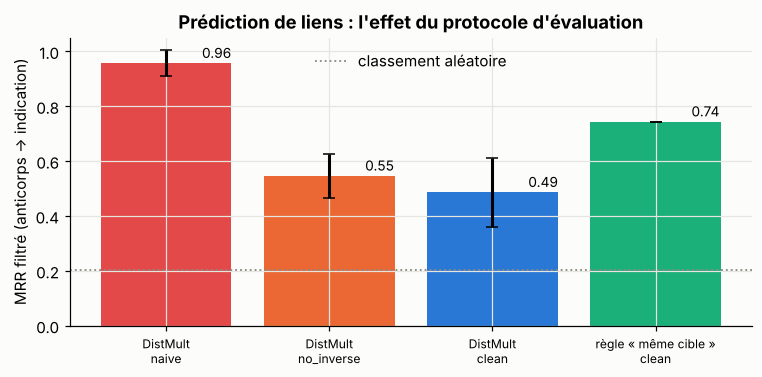

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
lab = [f"{r.model}\n{r.protocol}" for r in res.itertuples()]
cols = [PALETTE[7], PALETTE[1], PALETTE[0], PALETTE[2]]
ax.bar(range(len(res)), res.MRR, yerr=res.MRR_sd.fillna(0), capsize=4, color=cols)
for k, v in enumerate(res.MRR):
    ax.text(k + 0.22, v + 0.02, f"{v:.2f}", ha="left", fontsize=9)
ax.axhline(np.mean([1 / k for k in range(1, len(INDICATIONS) + 1)]), color="#8a8984", ls=":", lw=1.2, label="classement aléatoire")
ax.set_xticks(range(len(res))); ax.set_xticklabels(lab, fontsize=8); ax.set_ylabel("MRR filtré (anticorps → indication)")
ax.legend(loc="upper center")
ax.set_title("Prédiction de liens : l'effet du protocole d'évaluation"); ax.set_ylim(0, 1.05)
plt.show()

Ce que montre l'expérience (moyenne sur 5 graines, barres = écart-type) :
- en protocole **naïf**, DistMult paraît presque parfait (MRR ≈ 0,96) : il relit la réponse dans le triplet inverse resté à l'entraînement ;
- retirer les inverses fait chuter le MRR à environ 0,55 ; retirer aussi les chemins par les études le baisse encore un peu (≈ 0,49), mais l'écart est du même ordre que la variance entre graines. Avec 19 paires de test, on ne peut pas trancher : sur un vrai graphe, il faut des milliers de paires et plusieurs graines avant de conclure ;
- en protocole **propre**, la **règle « même cible »**, sans aucun apprentissage, fait nettement mieux que DistMult (0,74). Ici c'est en partie construit, puisque le générateur tire les indications à partir de la cible ; mais c'est aussi largement vrai dans la réalité (les indications suivent la biologie de la cible), d'où l'importance de rapporter cette baseline.

> 🎯 **Pour les travaux de repositionnement sur IMGT/mAb-KG** : (1) décrire explicitement, dans l'article, le traitement des relations inverses (`hasClinicalIndication` / `isClincicalIndicationOf`) et des chemins par les études cliniques lors du découpage ; (2) rapporter une **baseline par règle** (même cible, même mécanisme d'action) à côté des 28 modèles de PyKEEN ; (3) préférer un découpage **temporel** (indications ajoutées après une date) pour évaluer un vrai repositionnement. Si ces points sont déjà traités dans le préprint, une phrase explicite dans les méthodes suffira à rassurer les relecteurs ; sinon, ils changeront probablement les conclusions.

In [ ]:
# The same protocol with PyKEEN (real experiments): remove inverses and implying paths from training yourself,
# then evaluate with filtered ranking restricted to indication entities.
from pykeen.pipeline import pipeline
from pykeen.triples import TriplesFactory
import numpy as np

train_tf = TriplesFactory.from_labeled_triples(np.array(training_triples(TEST, "clean"), dtype=str))
test_tf = TriplesFactory.from_labeled_triples(np.array([(m, "imgt:hasClinicalIndication", i) for m, i in TEST], dtype=str),
                                              entity_to_id=train_tf.entity_to_id, relation_to_id=train_tf.relation_to_id)
result = pipeline(training=train_tf, testing=test_tf, model="BoxE", epochs=200,
                  negative_sampler="bernoulli", random_seed=0)
print(result.metric_results.get_metric("both.realistic.inverse_harmonic_mean_rank"))

## 7. En production : Fuseki, point d'accès en lecture seule, délais

```bash
# Load the IMGT/mAb-KG dump into a TDB2 database (offline, fast), then serve it READ-ONLY to the assistant
tdb2.tdbloader --loc databases/mabkg imgt_mabkg.ttl
./fuseki-server --tdb2 --loc=databases/mabkg /mabkg           # no --update: no /update endpoint exposed
# endpoint for the assistant: http://localhost:3030/mabkg/sparql
```

Dans un fichier de configuration Fuseki, fixe un **délai maximal** de requête (contexte `arq:queryTimeout`) : une requête générée par un LLM peut, sans le vouloir, produire un produit cartésien sur 150 000 triplets. Et si le graphe est servi avec un raisonneur, décide **explicitement** si l'assistant interroge le graphe normal ou le graphe inféré (IMGT propose les deux) : les réponses diffèrent, et l'assistant doit le dire.

## 8. Un serveur MCP pour IMGT/mAb-KG (et ProtAnnotML)

Le serveur expose : le **schéma** introspecté (ressource), la **liaison d'entités** (outil), la requête SPARQL **validée en lecture seule** (outil), et, pour relier les deux projets, l'**annotation d'une séquence** par ProtAnnotML (outil). Un agent peut alors répondre à « Annote cette séquence, puis dis-moi quels anticorps thérapeutiques utilisent le même gène IGHV ».

In [ ]:
# file: mabkg_server.py        pip install "mcp>=2" SPARQLWrapper rdflib requests
import re
import requests
from mcp.server import MCPServer
from rdflib.plugins.sparql import prepareQuery
from SPARQLWrapper import SPARQLWrapper, JSON

ENDPOINT = "http://localhost:3030/mabkg/sparql"                 # read-only dataset
PROTANNOT = "http://localhost:8000/annotate"                     # ProtAnnotML service (capstone pf06)
NS = {"imgt": "https://www.imgt.org/imgt-ontology#",            # PLACEHOLDER IRI: copy the real one from your Fuseki dataset
      "rdfs": "http://www.w3.org/2000/01/rdf-schema#",
      "rdf": "http://www.w3.org/1999/02/22-rdf-syntax-ns#", "skos": "http://www.w3.org/2004/02/skos/core#",
      "xsd": "http://www.w3.org/2001/XMLSchema#"}                # complete with the real prefixes of IMGT/mAb-KG
PREFIXES = "\n".join(f"PREFIX {k}: <{v}>" for k, v in NS.items())
mcp = MCPServer("imgt-mabkg")


def _select(query, timeout=15):
    ep = SPARQLWrapper(ENDPOINT); ep.setReturnFormat(JSON); ep.setTimeout(timeout); ep.setQuery(query)
    return [{k: v["value"] for k, v in b.items()} for b in ep.query().convert()["results"]["bindings"]]


@mcp.resource("mabkg://schema")
def schema() -> str:
    """Observed schema of IMGT/mAb-KG (classes, predicates with subject/object types and examples). Read before writing SPARQL."""
    return open("mabkg_schema.txt", encoding="utf-8").read()     # produced offline by the introspection queries (section 2)


@mcp.tool()
def find_entity(name: str, kind: str = "any") -> list[dict]:
    """Find IRIs of antibodies, targets or indications by name or synonym (exact first, then contains). kind: antibody|target|indication|any."""
    needle = name.lower().replace('"', "")
    q = PREFIXES + f"""
    SELECT DISTINCT ?s ?label WHERE {{
      ?s rdfs:label|skos:altLabel ?label .
      FILTER(CONTAINS(LCASE(STR(?label)), "{needle}"))
    }} LIMIT 20"""
    rows = _select(q)
    rows.sort(key=lambda r: (r["label"].lower() != needle, len(r["label"])))
    return rows[:10]


@mcp.tool()
def sparql_select(query: str, limit: int = 100) -> dict:
    """Run a READ-ONLY SPARQL SELECT on IMGT/mAb-KG. Standard prefixes are predeclared. Use only predicates from mabkg://schema."""
    if re.search(r"\b(INSERT|DELETE|LOAD|CLEAR|DROP|CREATE)\b", query, re.I):
        return {"error": "read-only endpoint"}
    full = PREFIXES + "\n" + query
    try:
        prepareQuery(full)
    except Exception as e:
        return {"error": f"SPARQL syntax error: {e}"}
    if not re.search(r"LIMIT\s+\d+", query, re.I):
        full += f"\nLIMIT {min(limit, 500)}"
    rows = _select(full)
    return {"rows": rows, "n": len(rows), "note": "empty result: check entity IRIs with find_entity" if not rows else ""}


@mcp.tool()
def annotate_sequence(sequence: str) -> dict:
    """Annotate an IG/TR protein sequence with ProtAnnotML (domains, IMGT numbering, FR/CDR, locus, V gene with abstention)."""
    return requests.post(PROTANNOT, json={"sequences": [sequence]}, timeout=60).json()[0]


if __name__ == "__main__":
    mcp.run()

> 🔐 Le contenu des réponses SPARQL (libellés, résumés de mécanismes) est du texte **non fiable** pour l'agent au sens du module 15 : il ne doit jamais être traité comme une instruction. Le serveur est en lecture seule, et aucun outil à effet de bord n'est exposé.

## 9. Un agent LangGraph : router, lier, interroger, vérifier

Pour un assistant destiné aux utilisateurs d'IMGT, un **workflow** explicite est préférable à un agent libre (module 18) : chaque étape est vérifiable et la boucle de réparation est bornée.

In [ ]:
import json
from typing import TypedDict
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END

model = init_chat_model("anthropic:claude-sonnet-5-5", temperature=0)
SCHEMA_TXT = open("mabkg_schema.txt", encoding="utf-8").read()
FEW_SHOT = json.load(open("mabkg_validated_queries.json"))         # [{"question": ..., "sparql": ...}] written by IMGT experts


class S(TypedDict, total=False):
    question: str
    entities: list
    query: str
    errors: list
    rows: list
    attempts: int
    answer: str


def link_node(state: S):
    mentions = model.invoke("List the antibody, target or disease names mentioned, one per line, nothing else.\n" + state["question"]).content
    ents = [find_entity(m.strip()) for m in mentions.splitlines() if m.strip()]          # MCP tool, or a direct call
    return {"entities": ents, "attempts": 0}


def generate_node(state: S):
    examples = "\n\n".join(f"Q: {e['question']}\nSPARQL: {e['sparql']}" for e in FEW_SHOT[:3])   # better: retrieve the 3 closest
    feedback = f"\nPrevious attempt failed: {state['errors']}" if state.get("errors") else ""
    q = model.invoke(f"Schema:\n{SCHEMA_TXT}\n\nExamples:\n{examples}\n\nEntities (IRIs): {state['entities']}\n"
                     f"Write ONE SPARQL SELECT query answering: {state['question']}{feedback}\nReturn only the query.").content
    return {"query": q.strip().strip("`"), "attempts": state["attempts"] + 1}


def execute_node(state: S):
    res = sparql_select(state["query"])
    if "error" in res:
        return {"errors": [res["error"]], "rows": []}
    return {"errors": [] if res["n"] else ["empty result"], "rows": res["rows"]}


def answer_node(state: S):
    if not state.get("rows"):
        return {"answer": "Je n'ai pas trouvé de réponse fiable dans IMGT/mAb-KG. Requête essayée :\n" + state.get("query", "")}
    text = model.invoke(f"Question: {state['question']}\nSPARQL used: {state['query']}\nRows: {state['rows'][:50]}\n"
                        "Answer in French using only these rows; list the antibodies by name; show the query at the end.").content
    return {"answer": text}


def after_execute(state: S):
    return "generate" if state["errors"] and state["attempts"] < 3 else "answer"


g = StateGraph(S)
g.add_node("link", link_node); g.add_node("generate", generate_node); g.add_node("execute", execute_node); g.add_node("answer", answer_node)
g.add_edge(START, "link"); g.add_edge("link", "generate"); g.add_edge("generate", "execute")
g.add_conditional_edges("execute", after_execute, ["generate", "answer"]); g.add_edge("answer", END)
assistant = g.compile()
print(assistant.invoke({"question": "Quels anticorps anti-PD-1 sont approuvés dans le mélanome ?"})["answer"])

> 📏 **Évaluer l'assistant** comme en section 4 : un jeu de 50 à 100 questions écrites avec l'équipe IMGT, une requête de référence chacune, et l'exactitude d'exécution suivie à chaque changement de modèle, de prompt ou d'exemples. Ajoute quelques questions **sans réponse** dans le graphe : l'assistant doit le dire, pas inventer.

## 10. Récapitulatif

| Étape | À retenir |
|---|---|
| Schéma | l'extraire du graphe (signatures observées), pas le supposer |
| Liaison | libellés + synonymes ; exact d'abord, flou signalé ; attention aux quasi-homonymes (PD-1 / PD-L1) |
| Text-to-SPARQL | valider (lecture seule, prédicats, LIMIT), réparer avec l'erreur ; évaluer par l'**exactitude d'exécution** |
| Erreurs non détectables | requêtes valides mais fausses : seul un jeu de référence les révèle |
| GraphRAG | voisinage par niveaux (anticorps, construction, produit, mode d'action), faits cités [Tn] |
| Prédiction de liens | retirer inverses **et** chemins impliquants ; baseline par règle ; split temporel |
| Production | Fuseki en lecture seule, délai de requête, graphe normal vs inféré explicite |
| Intégration | serveur MCP (schéma, liaison, SPARQL, ProtAnnotML) ; workflow LangGraph borné |

### 🏋️ Exercices

1. **Schéma réel.** Lance les requêtes d'introspection sur ton Fuseki IMGT/mAb-KG, et remplace le graphe fictif par un extrait réel (quelques milliers de triplets exportés en Turtle). Combien de signatures (type sujet, prédicat, type objet) ? Lesquelles surprennent ?
2. **Jeu d'évaluation.** Écris 30 questions réelles d'utilisateurs avec leur requête de référence (dont 5 sans réponse). Mesure l'exactitude d'exécution d'un vrai modèle avec et sans exemples few-shot récupérés par similarité.
3. **Fuite.** Reprends l'expérience de la section 6 avec PyKEEN sur IMGT/mAb-KG réel et le modèle qui a donné les meilleurs résultats dans tes travaux : quel écart de MRR entre protocole naïf et propre ? Que devient le classement des modèles ?
4. **Agent combiné.** Branche l'outil `annotate_sequence` et pose : « Voici une chaîne lourde : quel gène IGHV, et quels anticorps thérapeutiques utilisent le même ? ». Vérifie la réponse à la main.

<details><summary>Indications</summary>

3. Le classement des modèles peut changer : ceux qui exploitent bien les relations inverses (ce que DistMult, symétrique, fait facilement) sont favorisés par le protocole naïf.
4. La réponse doit tenir compte de l'abstention de ProtAnnotML : si le gène est incertain, l'agent doit le dire avant d'interroger le graphe.
</details>